# Section 4 — Final Model Diagnostics and Robustness

**ECON 430 Project 1 · 20 points**

[4(a)](#current-4a) · [4(b)](#current-4b) · [4(c)](#current-4c) · [4(d)](#current-4d) · [4(e)](#current-4e) · [4(f)](#current-4f) · [4(g)](#current-4g)

This is the current submission analysis. Requirements follow the [professor’s PDF](../project1-1%20%281%29.pdf). Section 4 letters organize its unlettered diagnostic bullets. The prior analysis is preserved verbatim in the historical appendix at the end; its old results/statuses do not describe the current model. Current Model 3 uses the explicit full-candidate significance rule in Section 3(d); the former seven-predictor model remains supporting evidence.

**Execution:** fresh Python kernel, working directory `notebooks/`; install the compatible project requirements. Input is the unchanged [4,139-space processed CSV](../data/processed/parking_cross_section.csv), built by [cleaning/03](cleaning/03_build_cross_section.ipynb). Main 01/06 are narrative; 02–05 reload their own inputs. [01](01_economic_theory.ipynb) · [02](02_data_description_eda.ipynb) · [03](03_variable_selection_models.ipynb) · [04](04_diagnostics_robustness.ipynb) · [05](05_results_interpretation.ipynb) · [06](06_limitations_extensions.ipynb).

<a id="current-4a"></a>

## 4(a) Linearity: Residuals vs. Fitted and RESET

**Requirement:** Residual/fitted plot and RESET test.

**Method:** Plot residuals/fitted values and execute squared-fitted RESET. **Evidence:** current code/outputs or cited substantive discussion immediately below. **Interpretation:** accompanies the evidence, including units and limitations. **Status:** Complete for analytical coverage; execution evidence is recorded separately, and no grade is guaranteed.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown

%matplotlib inline

root = Path.cwd().parent
parking_full = pd.read_csv(root / "data/processed/parking_cross_section.csv",
                          dtype={"SpaceID": str, "GEOID": str})
parking = parking_full.loc[parking_full["RateType"].isin(["FLAT", "TOD"])].copy()
dependent_variable = "occupancy_rate"
candidate_variables = [
    "price_midpoint", "time_limit_hours", "population_density", "median_income",
    "nearby_restaurant_retail_count", "drive_alone_share", "RateType", "MeterType",
    "housing_density", "transit_share", "walk_share", "nearby_business_count"
]
encoded = pd.get_dummies(parking[candidate_variables], drop_first=True, dtype=int)
data = pd.concat([parking[["occupancy_rate"]], encoded], axis=1).dropna().copy()
y = data["occupancy_rate"]
X = data.drop(columns="occupancy_rate")
assert parking_full["SpaceID"].is_unique
assert parking.loc[data.index, "SpaceID"].is_unique
print("Original / FLAT+TOD / common:", len(parking_full), len(parking), len(data))
print("Candidates / common-sample tracts:", X.shape[1], parking.loc[data.index, "GEOID"].nunique())
# Fixed rule: retain EVERY slope with conventional p < 0.05 in the
# original 12-candidate full OLS model, on the same complete-case sample.
# This is one screen, not repeated p-value deletion or hold-out tuning.
full_model = sm.OLS(y, sm.add_constant(X)).fit()
alpha = 0.05
predictors = [v for v in X.columns if full_model.pvalues[v] < alpha]
legacy_predictors = ["price_midpoint", "time_limit_hours", "population_density",
                     "nearby_restaurant_retail_count", "drive_alone_share",
                     "transit_share", "RateType_TOD"]
X1 = sm.add_constant(data[["price_midpoint"]])
X2 = sm.add_constant(data[["price_midpoint", "population_density", "nearby_restaurant_retail_count"]])
X3 = sm.add_constant(data[predictors])
model1 = sm.OLS(y, X1).fit()
model2 = sm.OLS(y, X2).fit()
model3 = sm.OLS(y, X3).fit()
hc1 = sm.OLS(y, X3).fit(cov_type="HC1")
legacy_model = sm.OLS(y, sm.add_constant(data[legacy_predictors])).fit()
assert set(predictors) == set(full_model.pvalues.drop("const").loc[lambda p: p < alpha].index)


Original / FLAT+TOD / common: 4139 4060 4016
Candidates / common-sample tracts: 12 45


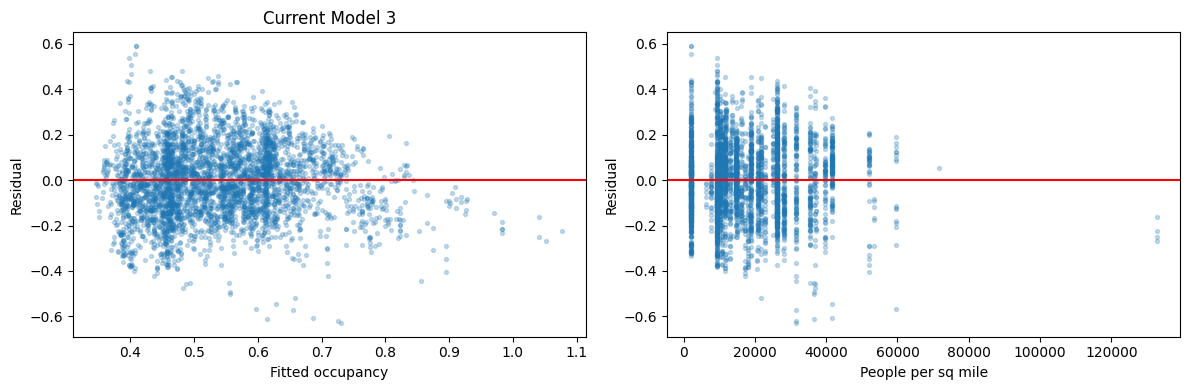

RESET: <F test: F=171.62862995827848, p=1.9889105344804053e-38, df_denom=4.01e+03, df_num=1>
Predictions outside [0,1]: 4


In [2]:
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset
from statsmodels.stats.stattools import jarque_bera
influence = model3.get_influence()
fitted, residuals = model3.fittedvalues, model3.resid
standardized = influence.resid_studentized_internal
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(fitted,residuals,s=8,alpha=.25); axes[0].axhline(0,color="red")
axes[0].set(xlabel="Fitted occupancy",ylabel="Residual",title="Current Model 3")
axes[1].scatter(data["population_density"],residuals,s=8,alpha=.25)
axes[1].axhline(0,color="red"); axes[1].set(xlabel="People per sq mile",ylabel="Residual")
plt.tight_layout(); plt.show()
reset = linear_reset(model3,power=2,test_type="fitted",use_f=True)
print("RESET:",reset)
print("Predictions outside [0,1]:",int((~fitted.between(0,1)).sum()))


RESET tests whether a squared fitted term adds explanatory power; rejection flags possible mean misspecification, not a unique remedy. Read the conventional test alongside heteroskedasticity evidence. Tract bands reflect repeated predictors; out-of-range predictions are left visible rather than clipped.

<a id="current-4b"></a>

## 4(b) Homoskedasticity: Breusch–Pagan, White, and Scale-Location

**Requirement:** Execute both tests and the scale-location plot.

**Method:** Execute BP/White, plot scale-location and compare conventional/HC1 uncertainty. **Evidence:** current code/outputs or cited substantive discussion immediately below. **Interpretation:** accompanies the evidence, including units and limitations. **Status:** Complete for analytical coverage; execution evidence is recorded separately, and no grade is guaranteed.

,LM statistic,LM p,F statistic,F p
Breusch–Pagan (Koenker default),167.020075,1.066254e-32,24.845784,2.109396e-33
White,374.994232,4.537699e-59,12.059144,2.045987e-62


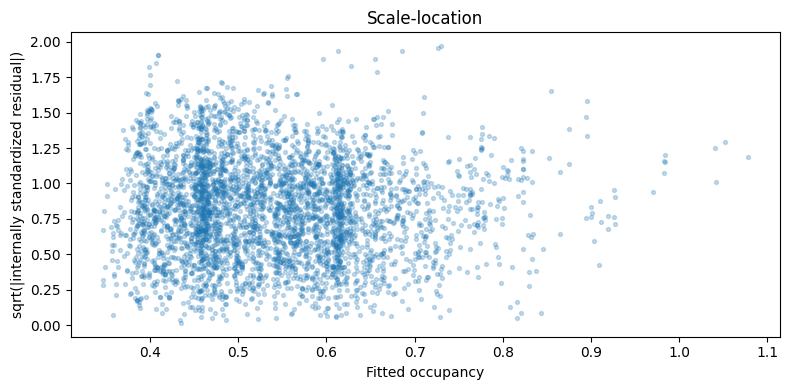

,Coefficient,OLS SE,HC1 SE,OLS p,HC1 p
const,0.319517,9.385660e-03,1.054971e-02,2.359190e-223,1.708228e-201
price_midpoint,0.051543,2.315093e-03,2.249493e-03,1.246231e-103,3.427946e-116
population_density,0.000004,2.160516e-07,2.273044e-07,3.645247e-72,5.182421e-68
nearby_restaurant_retail_count,-0.000534,4.216810e-05,3.871098e-05,4.115956e-36,2.411570e-43
transit_share,0.100461,4.491341e-02,4.596531e-02,2.535575e-02,2.884573e-02
walk_share,0.282333,2.863791e-02,2.673724e-02,1.135825e-22,4.589094e-26
nearby_business_count,0.000067,9.271826e-06,8.885822e-06,7.894375e-13,6.450594e-14
RateType_TOD,0.043567,7.052041e-03,8.099465e-03,7.141194e-10,7.489605e-08


In [3]:
bp = het_breuschpagan(residuals,X3)
white = het_white(residuals,X3)
variance_tests = pd.DataFrame([bp,white],index=["Breusch–Pagan (Koenker default)","White"],
                             columns=["LM statistic","LM p","F statistic","F p"])
display(variance_tests)
plt.figure(figsize=(8,4)); plt.scatter(fitted,np.sqrt(np.abs(standardized)),s=8,alpha=.25)
plt.xlabel("Fitted occupancy"); plt.ylabel("sqrt(|internally standardized residual|)")
plt.title("Scale-location"); plt.tight_layout(); plt.show()
uncertainty = pd.DataFrame({"Coefficient":model3.params,"OLS SE":model3.bse,
                           "HC1 SE":hc1.bse,"OLS p":model3.pvalues,"HC1 p":hc1.pvalues})
display(uncertainty)


The variance-test null is constant error variance; small p-values reject it. Final inference uses HC1, which keeps OLS coefficients but adjusts uncertainty under heteroskedasticity. HC1 does not fix endogeneity, omitted mean structure, selection or spatial dependence.

<a id="current-4c"></a>

## 4(c) Residual Normality: Q-Q, Jarque–Bera, and Histograms

**Requirement:** Show all three residual-normality diagnostics.

**Method:** Plot residual Q-Q/histogram and execute Jarque–Bera for the current model. **Evidence:** current code/outputs or cited substantive discussion immediately below. **Interpretation:** accompanies the evidence, including units and limitations. **Status:** Complete for analytical coverage; execution evidence is recorded separately, and no grade is guaranteed.

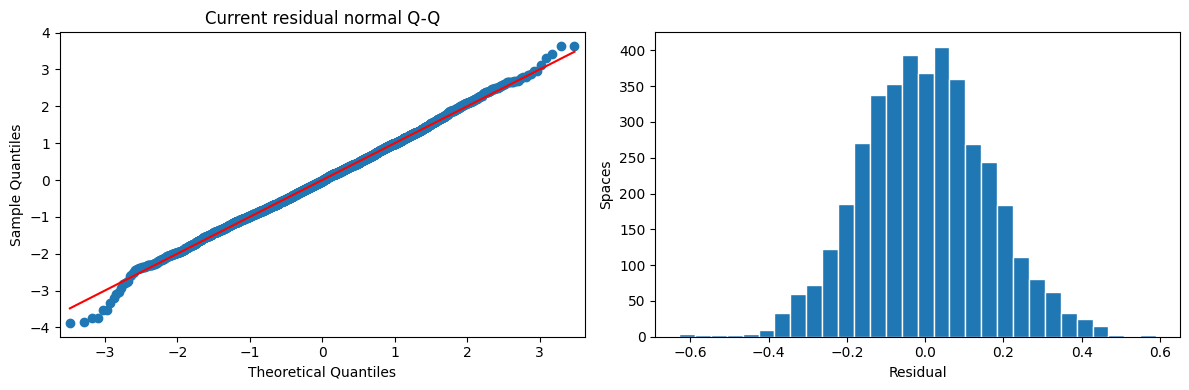

JB          8.075558
p           0.017637
skewness    0.069192
kurtosis    3.170616
dtype: float64

Jarque–Bera p=0.01764: **reject** normality at 5%. This conclusion applies to current Model 3, not the historical specification. A large sample can detect modest deviations; normality is not evidence of exogeneity or independent errors.

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
sm.qqplot(standardized,line="s",ax=axes[0]); axes[0].set_title("Current residual normal Q-Q")
axes[1].hist(residuals,bins=30,edgecolor="white"); axes[1].set(xlabel="Residual",ylabel="Spaces")
plt.tight_layout(); plt.show()
jb=jarque_bera(residuals)
display(pd.Series(jb,index=["JB","p","skewness","kurtosis"]))
display(Markdown(f"Jarque–Bera p={jb[1]:.4g}: **{'reject' if jb[1]<.05 else 'do not reject'}** normality at 5%. This conclusion applies to current Model 3, not the historical specification. A large sample can detect modest deviations; normality is not evidence of exogeneity or independent errors."))


<a id="current-4d"></a>

## 4(d) Outliers and Influence: Cook's Distance, Leverage, and DFBETAS

**Requirement:** The rubric requires Cook’s distance, leverage/residual plots and DFBETAS. DFBETAS remains missing because its addition was cancelled by the user.

**Method:** Compute Cook, leverage and studentized residuals with source IDs; leave DFBETAS unimplemented as requested. **Evidence:** current code/outputs or cited substantive discussion immediately below. **Interpretation:** accompanies the evidence, including units and limitations. **Status:** Partial — DFBETAS remains required but its addition was cancelled by the user.

,SpaceID,BlockFace,GEOID,Cook D,Leverage,Studentized residual
1487,CB3699,601 MAIN ST,06037207308,0.015170,0.009690,-3.526715
1223,CB3169,500 7TH ST,06037207712,0.010469,0.006718,-3.523912
1429,CB3568,700 GRAND AVE,06037207712,0.010217,0.005515,-3.845744
1464,CB3647,501 SPRING ST,06037207304,0.009177,0.025611,-1.671641
1466,CB3648B,501 SPRING ST,06037207304,0.008552,0.027150,-1.566028
1433,CB3570A,700 GRAND AVE,06037207712,0.007784,0.004127,-3.883366
1468,CB3651,601 SPRING ST,06037207304,0.007195,0.028216,-1.408124
1952,CB4486,700 BROADWAY,06037207303,0.007113,0.011367,2.225739
1139,CB2930,600 HILL ST,06037207305,0.004723,0.008326,2.122415
2739,HO482,6301 YUCCA ST,06037190201,0.003741,0.002146,-3.736709


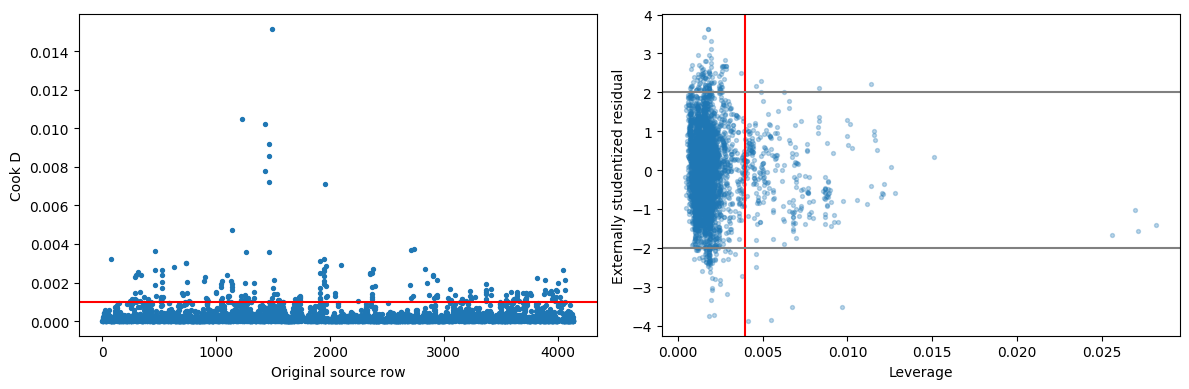

In [5]:
n,p = len(data),len(model3.params)
diagnostics = parking.loc[data.index,["SpaceID","BlockFace","GEOID"]].copy()
diagnostics["Cook D"] = influence.cooks_distance[0]
diagnostics["Leverage"] = influence.hat_matrix_diag
diagnostics["Studentized residual"] = influence.resid_studentized_external
display(diagnostics.nlargest(10,"Cook D"))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(diagnostics.index,diagnostics["Cook D"],s=8)
axes[0].axhline(4/n,color="red"); axes[0].set(xlabel="Original source row",ylabel="Cook D")
axes[1].scatter(diagnostics["Leverage"],diagnostics["Studentized residual"],s=8,alpha=.3)
axes[1].axvline(2*p/n,color="red"); axes[1].axhline(2,color="grey");axes[1].axhline(-2,color="grey")
axes[1].set(xlabel="Leverage",ylabel="Externally studentized residual")
plt.tight_layout(); plt.show()


Cook’s 4/n, leverage 2p/n and |studentized residual|>2 are complementary screening rules, not hypothesis-test guarantees or permanent cleaning rules. Source IDs above allow follow-up review; no source observation is deleted. **DFBETAS: Missing.** Its addition was explicitly cancelled by the user, so this required rubric component is not claimed complete.

<a id="current-4e"></a>

## 4(e) Robustness: 1,000-Replication Bootstrap vs. OLS

**Requirement:** Bootstrap all coefficients 1,000 times and compare to OLS.

**Method:** Fit 1,000 seeded row-bootstrap regressions and compare all parameters with OLS. **Evidence:** current code/outputs or cited substantive discussion immediately below. **Interpretation:** accompanies the evidence, including units and limitations. **Status:** Complete for analytical coverage; execution evidence is recorded separately, and no grade is guaranteed.

,OLS estimate,OLS SE,HC1 SE,Bootstrap mean,Bootstrap SE,Bootstrap 95% lower,Bootstrap 95% upper
const,0.319517,9.385660e-03,1.054971e-02,0.319355,1.059672e-02,0.298155,0.340040
price_midpoint,0.051543,2.315093e-03,2.249493e-03,0.051449,2.280507e-03,0.047164,0.055857
population_density,0.000004,2.160516e-07,2.273044e-07,0.000004,2.268313e-07,0.000004,0.000004
nearby_restaurant_retail_count,-0.000534,4.216810e-05,3.871098e-05,-0.000534,3.824563e-05,-0.000614,-0.000458
transit_share,0.100461,4.491341e-02,4.596531e-02,0.100415,4.539368e-02,0.010516,0.186203
walk_share,0.282333,2.863791e-02,2.673724e-02,0.282507,2.547086e-02,0.234080,0.333398
nearby_business_count,0.000067,9.271826e-06,8.885822e-06,0.000067,8.752566e-06,0.000049,0.000084
RateType_TOD,0.043567,7.052041e-03,8.099465e-03,0.043466,8.090968e-03,0.026551,0.059204


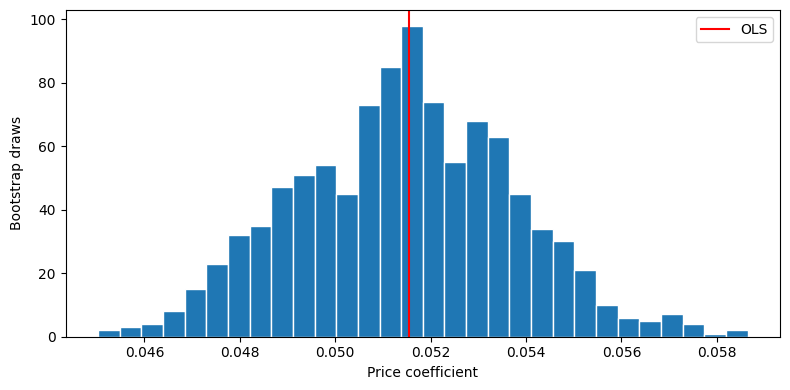

Completed bootstrap draws: 1000


In [6]:
np.random.seed(90095)
n_boot=1000
draws=[]
for draw in range(n_boot):
    sample=data.sample(n=len(data),replace=True)
    fit=sm.OLS(sample["occupancy_rate"],sm.add_constant(sample[predictors])).fit()
    draws.append(fit.params)
bootstrap=pd.DataFrame(draws)
bootstrap_summary=pd.DataFrame({"OLS estimate":model3.params,"OLS SE":model3.bse,
 "HC1 SE":hc1.bse,"Bootstrap mean":bootstrap.mean(),"Bootstrap SE":bootstrap.std(ddof=1),
 "Bootstrap 95% lower":bootstrap.quantile(.025),"Bootstrap 95% upper":bootstrap.quantile(.975)})
display(bootstrap_summary)
plt.figure(figsize=(8,4));plt.hist(bootstrap["price_midpoint"],bins=30,edgecolor="white")
plt.axvline(model3.params["price_midpoint"],color="red",label="OLS")
plt.xlabel("Price coefficient");plt.ylabel("Bootstrap draws");plt.legend();plt.tight_layout();plt.show()
print("Completed bootstrap draws:",len(bootstrap))


These are ordinary row-bootstrap percentile intervals with the selected predictor set held fixed. Compare centering and dispersion against OLS/HC1 in the table, not only price. Resampling rows assumes independent spaces; it does not reproduce model-selection uncertainty or clustered neighborhood shocks.

<a id="current-4f"></a>

## 4(f) Validation: 5-Fold or 10-Fold Cross-Validation and Out-of-Sample Accuracy

**Requirement:** Actual five-fold held-out fits and prediction errors.

**Method:** Refit the actual five training/held-out folds and report RMSE. **Evidence:** current code/outputs or cited substantive discussion immediately below. **Interpretation:** accompanies the evidence, including units and limitations. **Status:** Complete for analytical coverage; execution evidence is recorded separately, and no grade is guaranteed.

In [7]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
folds = KFold(n_splits=5, shuffle=True, random_state=10)
fits = {"Model 1": model1, "Model 2": model2, "Model 3 (rubric)": model3,
        "Prior seven (supporting)": legacy_model}
fold_errors = {}
for label, fit in fits.items():
    columns = [v for v in fit.model.exog_names if v != "const"]
    fold_errors[label] = -cross_val_score(LinearRegression(), data[columns], y,
                                        cv=folds, scoring="neg_root_mean_squared_error")
cv_results = pd.DataFrame(fold_errors, index=pd.Index(range(1, 6), name="Held-out fold"))
comparison = pd.DataFrame({
    label: {"Slopes": len(fit.params)-1, "N": int(fit.nobs), "R2": fit.rsquared,
            "Adjusted R2": fit.rsquared_adj, "AIC": fit.aic, "BIC": fit.bic,
            "In-sample RMSE": np.sqrt(np.mean(fit.resid**2)),
            "Mean 5-fold RMSE": fold_errors[label].mean(),
            "SD across folds": fold_errors[label].std(ddof=1)}
    for label, fit in fits.items()
}).T
display(cv_results.round(6))
display(comparison.round(6))


,Model 1,Model 2,Model 3 (rubric),Prior seven (supporting)
Held-out fold,,,,
1,0.175393,0.165986,0.162474,0.162926
2,0.179741,0.170995,0.163980,0.166667
3,0.179111,0.170807,0.163985,0.167118
4,0.176845,0.165379,0.162830,0.164252
5,0.176728,0.167872,0.160709,0.165612


,Slopes,N,R2,Adjusted R2,AIC,BIC,In-sample RMSE,Mean 5-fold RMSE,SD across folds
Model 1,1.0,4016.0,0.156775,0.156565,-2483.670513,-2471.074430,0.177522,0.177564,0.001807
Model 2,3.0,4016.0,0.243498,0.242932,-2915.517259,-2890.325092,0.168146,0.168208,0.002626
Model 3 (rubric),7.0,4016.0,0.294138,0.292905,-3185.769994,-3135.385661,0.162421,0.162796,0.001349
Prior seven (supporting),7.0,4016.0,0.273623,0.272354,-3070.712410,-3020.328077,0.164764,0.165315,0.001732


This is actual five-fold computation, not a table of copied historical scores. Seed 10 and identical folds make the fixed-specification comparison reproducible; each fit uses its training rows only. The limitations of prior selection and geographically shared folds remain as stated in 3(e). RMSE is in occupancy fractions; multiplying by 100 yields percentage points.

<a id="current-4g"></a>

## 4(g) OLS Assumption Violations and Implications

**Requirement:** Discuss actual results and retain feasible sensitivity checks.

**Method:** Interpret current tests and refit existing feasible specification/sample sensitivities. **Evidence:** current code/outputs or cited substantive discussion immediately below. **Interpretation:** accompanies the evidence, including units and limitations. **Status:** Complete for analytical coverage; execution evidence is recorded separately, and no grade is guaranteed.

In [8]:
keep=diagnostics["Cook D"]<=4/n
cook_model=sm.OLS(y.loc[keep],X3.loc[keep]).fit(cov_type="HC1")
log_data=data.copy();log_data["log_population_density"]=np.log(log_data["population_density"])
log_predictors=["log_population_density" if v=="population_density" else v for v in predictors]
log_ols=sm.OLS(y,sm.add_constant(log_data[log_predictors])).fit()
log_fit=sm.OLS(y,sm.add_constant(log_data[log_predictors])).fit(cov_type="HC1")
log_reset=linear_reset(log_ols,power=2,test_type="fitted",use_f=True)
days_data=data.loc[parking.loc[data.index,"active_days"].ge(28)]
days_fit=sm.OLS(days_data["occupancy_rate"],sm.add_constant(days_data[predictors])).fit(cov_type="HC1")
all_encoded=pd.concat([parking[["occupancy_rate"]],encoded],axis=1)
income_data=all_encoded[["occupancy_rate",*predictors]].dropna()
income_fit=sm.OLS(income_data["occupancy_rate"],sm.add_constant(income_data[predictors])).fit(cov_type="HC1")
check_fits={"Current primary":hc1,"Cook <=4/n":cook_model,"Log density":log_fit,
            "At least 28 active days":days_fit,"Restore missing-income spaces":income_fit}
robustness=pd.DataFrame({name:{"N":int(f.nobs),"Price":f.params["price_midpoint"],
 "HC1 lower":f.conf_int().loc["price_midpoint",0],"HC1 upper":f.conf_int().loc["price_midpoint",1],
 "Adjusted R2":f.rsquared_adj} for name,f in check_fits.items()}).T
display(robustness)
tests=pd.DataFrame({"Statistic":[bp[0],white[0],float(reset.fvalue),jb[0]],
                    "p":[bp[1],white[1],float(reset.pvalue),jb[1]]},
                   index=["BP LM","White LM","RESET F","Jarque–Bera"])
display(tests)
print("Log-density RESET p:",float(log_reset.pvalue))
display(Markdown(f"Current Model 3: **{'reject' if bp[1]<.05 else 'do not reject'}** constant variance (BP), **{'reject' if white[1]<.05 else 'do not reject'}** constant variance (White), **{'reject' if float(reset.pvalue)<.05 else 'do not reject'}** the RESET null, and **{'reject' if jb[1]<.05 else 'do not reject'}** residual normality at 5%. Read the plots and limitations alongside these decisions; HC1 does not repair a misspecified conditional mean."))
table_dir=root/"reports/tables";table_dir.mkdir(parents=True,exist_ok=True)
(table_dir/"current_diagnostics.json").write_text(json.dumps({
 "predictors":predictors,"n":len(data),"tests":json.loads(tests.to_json(orient="index")),
 "dfbetas_status":"Missing: addition cancelled by user",
 "bootstrap_draws":len(bootstrap),"bootstrap":json.loads(bootstrap_summary.to_json(orient="index")),
 "robustness":json.loads(robustness.to_json(orient="index"))},indent=2))


,N,Price,HC1 lower,HC1 upper,Adjusted R2
Current primary,4016.0,0.051543,0.047134,0.055952,0.292905
Cook <=4/n,3801.0,0.053297,0.049500,0.057094,0.369093
Log density,4016.0,0.052188,0.047825,0.056551,0.285781
At least 28 active days,1609.0,0.050041,0.042344,0.057738,0.261633
Restore missing-income spaces,4060.0,0.053335,0.048833,0.057837,0.289732


,Statistic,p
BP LM,167.020075,1.066254e-32
White LM,374.994232,4.537699e-59
RESET F,171.628630,1.988911e-38
Jarque–Bera,8.075558,1.763660e-02


Log-density RESET p: 6.253279091116574e-33


Current Model 3: **reject** constant variance (BP), **reject** constant variance (White), **reject** the RESET null, and **reject** residual normality at 5%. Read the plots and limitations alongside these decisions; HC1 does not repair a misspecified conditional mean.

3883

Heteroskedasticity, mean specification, possible tail deviations and within-tract/spatial dependence qualify inference. Conditional price associations are not causal demand responses; correlated and later-vintage regressors can reflect omitted demand. The common-sample, log-density, Cook and ≥28-day checks are separate comparisons, not new cleaning rules. The saved outcome remains unchanged. Raw 12/48-hour, expanded 20-day and Sunday-reporting sensitivities require original sensor inputs and remain proposed extensions rather than invented results.

## Section Summary and Rubric Coverage

4(a), 4(b), 4(c), 4(d), 4(e), 4(f), 4(g) have current methods/evidence or substantive discussion. Computational completion is accepted only after clean-kernel execution passes; names and syllabus review are deferred to final packaging by the group. No grade or causal finding is guaranteed. The historical material below is preserved supporting work, not current status evidence.

**4(d): Partial. DFBETAS is not implemented; the user cancelled its addition.**

# Historical analysis preserved before rubric completion

Everything below is retained verbatim from commit `96d4bb1`. Its old notebook numbers, model definitions, diagnostic conclusions and compliance claims are historical. Use the current analysis above for submission results. No original calculation, explanation, figure or output has been removed.

# Section 4 — Final Model Diagnostics and Robustness

**Assignment Section 4: 20 points.** This notebook organizes the existing final model diagnostics and robustness material without changing the analysis.

Authority: [professor’s assignment PDF](../project1-1%20%281%29.pdf), pp. 2–4; [exhaustive evidence audit](../docs/rubric_compliance_audit.md). Requirements are paraphrased in each subsection. Section 4 letters are organizational labels; the PDF uses diagnostic bullets. Historical numbered headings and forward-looking statements inside preserved cells refer to the original eight-notebook workflow; use this roadmap and the [cell migration audit](../docs/notebook_restructure_audit.md) for current locations. Historical compliance claims are preserved as source material; the new evidence audit supersedes them.

### Roadmap

- [4(a)](#rubric-4a)
- [4(b)](#rubric-4b)
- [4(c)](#rubric-4c)
- [4(d)](#rubric-4d)
- [4(e)](#rubric-4e)
- [4(f)](#rubric-4f)
- [4(g)](#rubric-4g)

### Dependencies and navigation

[Cleaning pipeline](cleaning/03_build_cross_section.ipynb) → [fixed cross-section](../data/processed/parking_cross_section.csv). Run each notebook with its own fresh Python kernel and working directory `notebooks/`. Sections 1 and 6 are narrative; sections 2–5 reload their own inputs. [Theory](01_economic_theory.ipynb) · [EDA](02_data_description_eda.ipynb) · [Models](03_variable_selection_models.ipynb) · [Diagnostics](04_diagnostics_robustness.ipynb) · [Results](05_results_interpretation.ipynb) · [Limitations](06_limitations_extensions.ipynb).

### Reproduce the common sample and unchanged models

# 07 — Regression Diagnostics and Robustness

I check the preferred Model 3 from Notebook 06, keeping its seven predictors and 4,016-space sample unchanged. I examine residuals, variance and functional form, then compare influence sensitivity and a 1,000-replication bootstrap. The full-sample OLS model remains the primary specification throughout.

I reviewed `project1-1.pdf`, `Regression_Lecture0.ipynb`, `Regression_Lecture1.ipynb`, `Regression_Lecture2.ipynb`, their available numbered copies, and `Case_1_430_Lab.ipynb` in Downloads, together with Notebooks 01 and 04–06. Lecture 1 supplies residual/normality plots and leverage screens; Lecture 2 supplies variance tests, RESET, influence plots, HC1 standard errors, and bootstrap examples. Methods not found in those materials are identified below rather than added silently.

## 1. Load the data and reproduce Notebook 06

I apply the same FLAT + TOD restriction and complete-case variable list as Notebook 06. Income is included only in the sample restriction to match Notebook 05, not as a predictor in any of the three models. I preserve the original row index so diagnostics can be linked back to the correct SpaceID and BlockFace.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset

%matplotlib inline

parking = pd.read_csv(
    "../data/processed/parking_cross_section.csv",
    dtype={"SpaceID": str, "GEOID": str}
)
print("Original observations:", len(parking))

parking = parking[parking["RateType"].isin(["FLAT", "TOD"])].copy()
parking["RateType_TOD"] = (parking["RateType"] == "TOD").astype(int)
print("FLAT + TOD observations:", len(parking))

Original observations: 4139
FLAT + TOD observations: 4060


In [2]:
variables = [
    "occupancy_rate", "price_midpoint", "time_limit_hours",
    "population_density", "nearby_restaurant_retail_count",
    "drive_alone_share", "transit_share", "RateType_TOD", "median_income"
]
print("Missing values before the common-sample restriction:")
print(parking[variables].isnull().sum())

data = parking[variables].dropna().copy()
y = data["occupancy_rate"]
print("Comparison observations:", len(data))
print("Unique SpaceIDs:", parking.loc[data.index, "SpaceID"].nunique())
print("Duplicate SpaceIDs:", parking.loc[data.index, "SpaceID"].duplicated().sum())
print("Census tracts:", parking.loc[data.index, "GEOID"].nunique())

Missing values before the common-sample restriction:
occupancy_rate                     0
price_midpoint                     0
time_limit_hours                   0
population_density                 0
nearby_restaurant_retail_count     0
drive_alone_share                  0
transit_share                      0
RateType_TOD                       0
median_income                     44
dtype: int64
Comparison observations: 4016
Unique SpaceIDs: 4016
Duplicate SpaceIDs: 0
Census tracts: 45


In [3]:
X1 = sm.add_constant(data[["price_midpoint"]])
model1 = sm.OLS(y, X1).fit()

X2 = sm.add_constant(data[[
    "price_midpoint", "population_density",
    "nearby_restaurant_retail_count"
]])
model2 = sm.OLS(y, X2).fit()

In [4]:
predictors = [
    "price_midpoint", "time_limit_hours", "population_density",
    "nearby_restaurant_retail_count", "drive_alone_share",
    "transit_share", "RateType_TOD"
]
X3 = sm.add_constant(data[predictors])
model3 = sm.OLS(y, X3).fit()

model_check = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "N": [int(model1.nobs), int(model2.nobs), int(model3.nobs)],
    "Adjusted R2": [model1.rsquared_adj, model2.rsquared_adj, model3.rsquared_adj],
    "AIC": [model1.aic, model2.aic, model3.aic],
    "BIC": [model1.bic, model2.bic, model3.bic]
})
model_check.round(5)

,Model,N,Adjusted R2,AIC,BIC
0,Model 1,4016,0.15657,-2483.67051,-2471.07443
1,Model 2,4016,0.24293,-2915.51726,-2890.32509
2,Model 3,4016,0.27235,-3070.71241,-3020.32808


In [5]:
coefficient_check = pd.DataFrame({
    "Model 1": model1.params,
    "Model 2": model2.params,
    "Model 3": model3.params
})
coefficient_check.style.format("{:.6g}", na_rep="—")

,Model 1,Model 2,Model 3
RateType_TOD,—,—,0.0330042
const,0.42375,0.392626,0.456337
drive_alone_share,—,—,-0.198101
nearby_restaurant_retail_count,—,-0.000228152,-0.000321282
population_density,—,4.05622e-06,4.57052e-06
price_midpoint,0.0545148,0.0599909,0.0556328
time_limit_hours,—,—,0.00487929
transit_share,—,—,0.0196471


All three models reproduce Notebook 06 on 4,016 unique spaces in 45 tracts. Their adjusted R² values are 0.15657, 0.24293, and 0.27235; AIC values are −2,483.67, −2,915.52, and −3,070.71, with matching coefficients and BIC values. Notebook 06 provisionally preferred Model 3 on fit and validation criteria, so the detailed checks below focus on that model.

<a id="rubric-4a"></a>

## 4(a) Linearity: Residuals vs. Fitted and RESET

**Requirement:** Show residuals versus fitted values and test specification with RESET.

**Method:** Retain residual panels, RESET and the existing log-density sensitivity.

**Evidence:** Original 07 cells 8–11 and 20–25.

**Interpretation:** RESET rejects; log density preserves the price sign but does not repair the functional form.

**Status: Complete.** 

## 2. Inspect the residual plots

I calculate fitted occupancy, residuals, and internally standardized residuals using the lecture approach. I plot residuals against fitted occupancy, price, and population density to look for changing spread or systematic patterns. The histogram gives a first view of the residual distribution without deleting unusual observations.

In [6]:
fitted = model3.fittedvalues
residuals = model3.resid
influence = model3.get_influence()
standardized = influence.resid_studentized_internal

print("Fitted occupancy outside [0, 1]:", (~fitted.between(0, 1)).sum())
residuals.describe()

Fitted occupancy outside [0, 1]: 4


count    4.016000e+03
mean    -3.244116e-13
std      1.647846e-01
min     -6.240984e-01
25%     -1.125996e-01
50%     -6.126102e-04
75%      1.102839e-01
max      5.685229e-01
dtype: float64

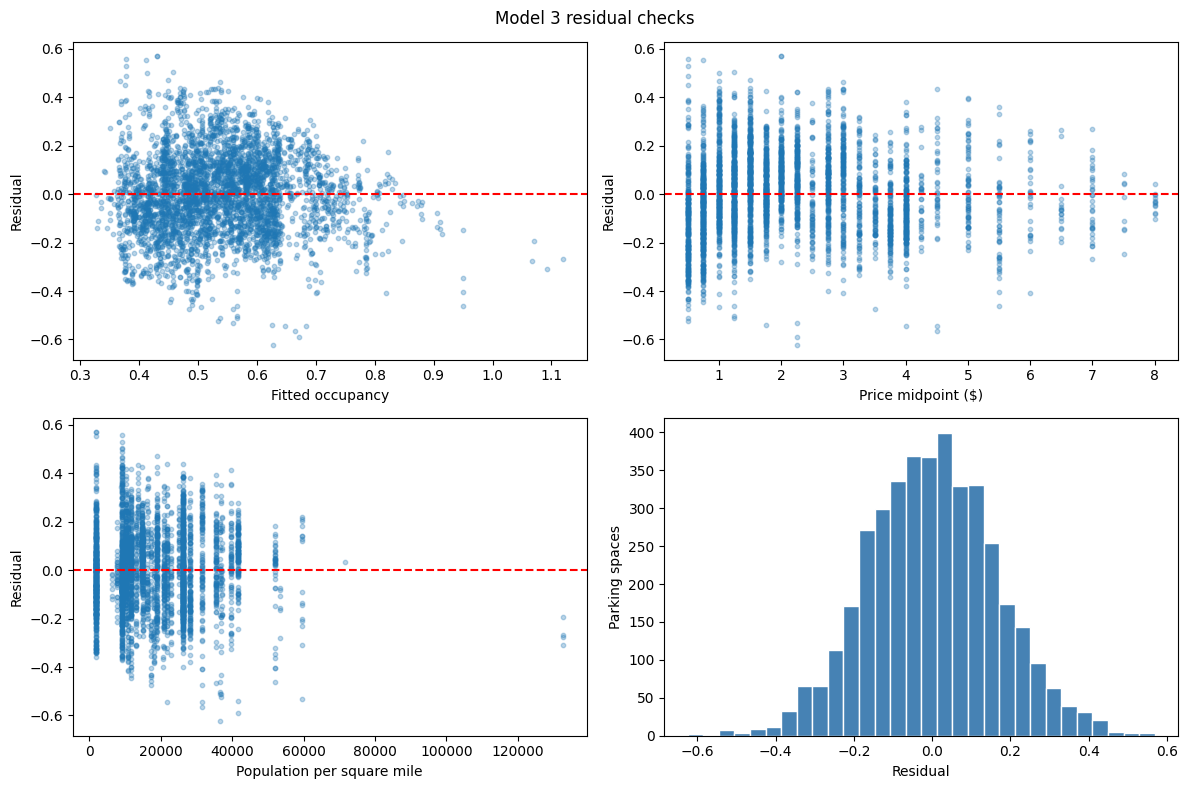

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].scatter(fitted, residuals, s=10, alpha=0.3)
axes[0, 0].set_xlabel("Fitted occupancy")
axes[0, 1].scatter(data["price_midpoint"], residuals, s=10, alpha=0.3)
axes[0, 1].set_xlabel("Price midpoint ($)")
axes[1, 0].scatter(data["population_density"], residuals, s=10, alpha=0.3)
axes[1, 0].set_xlabel("Population per square mile")

axes[0, 0].axhline(0, color="red", linestyle="--")
axes[0, 1].axhline(0, color="red", linestyle="--")
axes[1, 0].axhline(0, color="red", linestyle="--")
axes[0, 0].set_ylabel("Residual")
axes[0, 1].set_ylabel("Residual")
axes[1, 0].set_ylabel("Residual")
axes[1, 1].hist(residuals, bins=30, color="steelblue", edgecolor="white")
axes[1, 1].set_xlabel("Residual")
axes[1, 1].set_ylabel("Parking spaces")
fig.suptitle("Model 3 residual checks")
fig.tight_layout()
plt.show()

Residuals are centered near zero overall but range from about −0.624 to 0.569. The spread is not uniform across fitted values, and shared tract measurements create vertical bands in the density plot. Four fitted values exceed one, which is another limitation of using an unconstrained linear model for a bounded outcome. These plots motivate the formal tests below; I do not clip predictions or alter the model.

## 5. Check the linear functional form

I use the lecture's Ramsey RESET approach, adding the square of fitted values in an auxiliary test. The null is that this added term is unnecessary. A rejection points to a possible specification problem, not to the particular variable or transformation that would fix it.

In [11]:
reset = linear_reset(model3, power=2, test_type="fitted", use_f=True)
print(reset)

<F test: F=122.0777512836214, p=5.604940901584903e-28, df_denom=4.01e+03, df_num=1>


RESET gives **F = 122.078** and **p = 5.60 × 10⁻²⁸**, suggesting a problem with the current linear specification. Because this is the conventional test and heteroskedasticity is present, I read it alongside the plots rather than treating it as an isolated diagnosis. The right-tailed, strictly positive density variable motivates the lecture’s linear-log alternative below. I keep the original specification as primary.

<a id="rubric-4b"></a>

## 4(b) Homoskedasticity: Breusch–Pagan, White, and Scale-Location

**Requirement:** Provide BP, White and scale-location diagnostics.

**Method:** Retain both tests, plot and HC1 comparison.

**Evidence:** Original 07 cells 15–19.

**Interpretation:** Both tests reject constant variance; HC1 does not address shared-tract dependence.

**Status: Complete.** 

## 4. Check constant variance and compare robust uncertainty

I use the lecture's scale-location plot, Breusch–Pagan test, and White test. Both tests have a null of constant error variance; I report their LM and F versions without treating them as separate independent checks. The scale-location plot uses the square root of absolute internally standardized residuals.

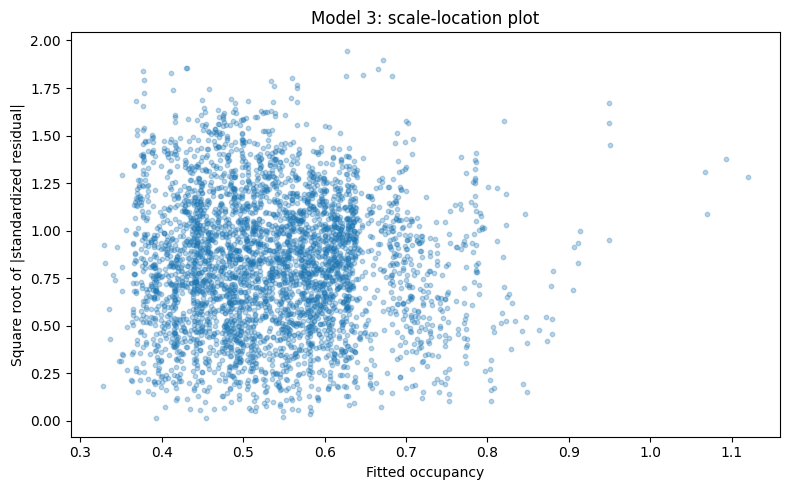

,Test,LM statistic,LM p-value,F statistic,F p-value
0,Breusch–Pagan (default Koenker version),207.230,3.374e-41,31.153,2.605e-42
1,White,394.973,4.755e-63,12.772,8.185e-67


In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fitted, np.sqrt(np.abs(standardized)), s=10, alpha=0.3)
ax.set_xlabel("Fitted occupancy")
ax.set_ylabel("Square root of |standardized residual|")
ax.set_title("Model 3: scale-location plot")
fig.tight_layout()
plt.show()

bp = het_breuschpagan(residuals, X3)
white = het_white(residuals, X3)
variance_tests = pd.DataFrame({
    "Test": ["Breusch–Pagan (default Koenker version)", "White"],
    "LM statistic": [bp[0], white[0]],
    "LM p-value": [bp[1], white[1]],
    "F statistic": [bp[2], white[2]],
    "F p-value": [bp[3], white[3]]
})
variance_tests.style.format({
    "LM statistic": "{:.3f}", "LM p-value": "{:.3e}",
    "F statistic": "{:.3f}", "F p-value": "{:.3e}"
})

Both tests reject constant variance: the Breusch–Pagan LM p-value is **3.37 × 10⁻⁴¹**, and White's is **4.75 × 10⁻⁶³**. Conventional standard errors, intervals, and tests therefore need caution; changing the covariance estimate does not change the OLS coefficients or fix a misspecified mean.

Lecture 2 mentions the HC0–HC3 family, but its worked comparisons use **HC1**, not HC3. I follow that demonstrated HC1 code below rather than claim to have a worked HC3 example. This comparison still treats different spaces as independent.

In [10]:
model3_hc1 = sm.OLS(y, X3).fit(cov_type="HC1")

robust_comparison = pd.DataFrame({
    "Coefficient": model3.params,
    "OLS SE": model3.bse,
    "HC1 SE": model3_hc1.bse,
    "OLS p-value": model3.pvalues,
    "HC1 p-value": model3_hc1.pvalues,
    "HC1 95% lower": model3_hc1.conf_int()[0],
    "HC1 95% upper": model3_hc1.conf_int()[1]
})
print("Largest coefficient change:", (model3.params - model3_hc1.params).abs().max())
robust_comparison.style.format({
    "Coefficient": "{:.6g}", "OLS SE": "{:.6g}", "HC1 SE": "{:.6g}",
    "OLS p-value": "{:.3e}", "HC1 p-value": "{:.3e}",
    "HC1 95% lower": "{:.6g}", "HC1 95% upper": "{:.6g}"
})

Largest coefficient change: 0.0


,Coefficient,OLS SE,HC1 SE,OLS p-value,HC1 p-value,HC1 95% lower,HC1 95% upper
const,0.456337,0.0157939,0.0171155,6.470e-167,1.291e-156,0.422792,0.489883
price_midpoint,0.0556328,0.00236136,0.00232226,4.731e-115,7.931e-127,0.0510813,0.0601844
time_limit_hours,0.00487929,0.00294796,0.00313717,9.797e-02,1.199e-01,-0.00126946,0.011028
population_density,4.57052e-06,2.21771e-07,2.37074e-07,8.803e-90,8.077e-83,4.10586e-06,5.03518e-06
nearby_restaurant_retail_count,-0.000321282,2.29852e-05,2.4298e-05,2.189e-43,6.502e-40,-0.000368905,-0.000273659
drive_alone_share,-0.198101,0.0208314,0.0211007,3.195e-21,6.095e-21,-0.239458,-0.156744
transit_share,0.0196471,0.0468362,0.0452127,6.749e-01,6.639e-01,-0.0689682,0.108262
RateType_TOD,0.0330042,0.00731608,0.00857071,6.631e-06,1.177e-04,0.0162059,0.0498025


The price estimate stays **0.05563**; its HC1 standard error is **0.002322**, versus **0.002361** conventionally, with an HC1 95% interval of **0.05108 to 0.06018**. Its positive association remains statistically clear under this correction, while time limit and transit share remain uncertain. HC1 uses statsmodels' default normal-reference inference here; it does not account for within-tract dependence.

### Supporting Evidence — Linearity follow-up using log density

This original sensitivity belongs to 4(a), but executes here after the HC1 reference fit it uses has been defined. The original calculation and primary model remain unchanged.

### A simple log-density alternative

Lecture 1 demonstrates replacing a positive, skewed explanatory variable with its natural log. I replace population density only, keeping the same observations, outcome and other six predictors; this is a sensitivity check rather than a new primary model.

In [12]:
log_data = data.copy()
assert log_data["population_density"].gt(0).all()
log_data["log_population_density"] = np.log(log_data["population_density"])
log_predictors = ["log_population_density" if v == "population_density" else v for v in predictors]
log_X = sm.add_constant(log_data[log_predictors])
log_model = sm.OLS(y, log_X).fit()
log_hc1 = sm.OLS(y, log_X).fit(cov_type="HC1")
log_reset = linear_reset(log_model, power=2, test_type="fitted", use_f=True)
log_comparison = pd.DataFrame({
    "Specification": ["Original density (primary)", "Log density (robustness)"],
    "N": [int(model3.nobs), int(log_model.nobs)],
    "Price coefficient": [model3.params["price_midpoint"], log_model.params["price_midpoint"]],
    "HC1 price SE": [model3_hc1.bse["price_midpoint"], log_hc1.bse["price_midpoint"]],
    "Adjusted R2": [model3.rsquared_adj, log_model.rsquared_adj],
    "AIC": [model3.aic, log_model.aic],
    "BIC": [model3.bic, log_model.bic],
    "RESET p-value": [float(reset.pvalue), float(log_reset.pvalue)]
})
log_comparison.style.format({"Price coefficient": "{:.6f}", "HC1 price SE": "{:.6f}",
    "Adjusted R2": "{:.5f}", "AIC": "{:.2f}", "BIC": "{:.2f}", "RESET p-value": "{:.3e}"})

,Specification,N,Price coefficient,HC1 price SE,Adjusted R2,AIC,BIC,RESET p-value
0,Original density (primary),4016,0.055633,0.002322,0.27235,-3070.71,-3020.33,5.605e-28
1,Log density (robustness),4016,0.055160,0.002309,0.27325,-3075.69,-3025.30,1.416e-19


Price changes only from **0.05563 to 0.05516**, or **5.56 to 5.52 percentage points per dollar**. Adjusted R² improves slightly from **0.27235 to 0.27325** and AIC falls to **−3,075.69**, but RESET still rejects (**p ≈ 1.42 × 10⁻¹⁹**). This small transformation preserves the price conclusion without resolving the functional-form problem.

<a id="rubric-4c"></a>

## 4(c) Residual Normality: Q-Q, Jarque–Bera, and Histograms

**Requirement:** Provide all three residual normality checks.

**Method:** Retain Q-Q/JB cells and the residual histogram within 4(a)’s shared panel.

**Evidence:** Original 07 cells 12–14 and cell 10.

**Interpretation:** JB p=0.1469 does not reject normality; this does not validate other assumptions.

**Status: Complete.** 

## 3. Check residual normality

I compare internally standardized residuals with normal quantiles and use the Jarque–Bera test, whose null is normal residuals. The histogram is shown in the preceding section rather than repeated here. With a large sample, a test can detect small departures, and failing to reject is not proof of normality.

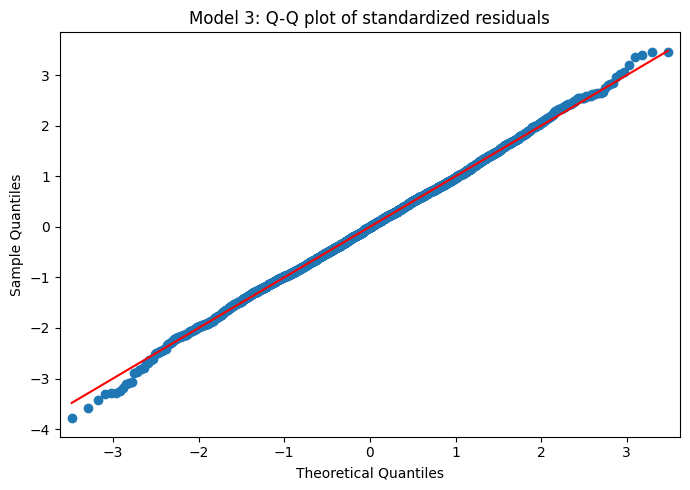

JB statistic    3.835976
P-value         0.146902
Skewness        0.031068
Kurtosis        3.138070
dtype: float64

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
sm.qqplot(standardized, line="s", ax=ax)
ax.set_title("Model 3: Q-Q plot of standardized residuals")
fig.tight_layout()
plt.show()

jb = jarque_bera(residuals)
normality = pd.Series(jb, index=["JB statistic", "P-value", "Skewness", "Kurtosis"])
normality

Jarque–Bera is **3.836**, with **p = 0.1469**, so I do not reject residual normality at 5%. Skewness is close to zero and kurtosis is about 3.138; the Q-Q plot is close to the reference line in the center with some tail departures. This result says nothing by itself about constant variance, independence, or the correctness of the conditional mean.

<a id="rubric-4d"></a>

## 4(d) Outliers and Influence: Cook's Distance, Leverage, and DFBETAS

**Requirement:** Provide Cook’s plot, leverage versus residuals and DFBETAS.

**Method:** Retain Cook/leverage/studentized-residual screens and existing exclusion sensitivity.

**Evidence:** Original 07 cells 26–34.

**Interpretation:** Screens overlap and do not prove bad records. DFBETAS is mentioned but never computed.

**Status: Partial.** DFBETAS implementation, saved results and interpretation are Missing; no new diagnostic is introduced in this reorganization.

## 6. Screen for influential observations

I link Cook's distance, leverage, and externally studentized residuals back to the unchanged source-row index and parking identifiers. I use the requested Cook's rule **4/n**, plus Lecture 1's **2p/n** leverage rule and **|studentized residual| > 2**, where p includes the intercept. These are screening rules, not evidence that a record is incorrect; the 4/n cutoff is supplied in the project instructions rather than shown as a worked lecture cutoff.

In [13]:
diagnostics = parking.loc[data.index, ["SpaceID", "BlockFace", "GEOID"]].copy()
diagnostics["cooks_d"] = influence.cooks_distance[0]
diagnostics["hat_diag"] = influence.hat_matrix_diag
diagnostics["studentized_residual"] = influence.resid_studentized_external

n = int(model3.nobs)
p = len(model3.params)
cook_cutoff = 4 / n
leverage_cutoff = 2 * p / n

diagnostics["cook_flag"] = diagnostics["cooks_d"] > cook_cutoff
diagnostics["leverage_flag"] = diagnostics["hat_diag"] > leverage_cutoff
diagnostics["residual_flag"] = diagnostics["studentized_residual"].abs() > 2

print("Rows align with the model:", diagnostics.index.equals(model3.model.data.row_labels))
print("n, p (including intercept):", n, p)
print("Cook cutoff:", cook_cutoff)
print("Leverage cutoff:", leverage_cutoff)
diagnostics[["cook_flag", "leverage_flag", "residual_flag"]].sum()

Rows align with the model: True
n, p (including intercept): 4016 8
Cook cutoff: 0.00099601593625498
Leverage cutoff: 0.00398406374501992


cook_flag        249
leverage_flag    136
residual_flag    189
dtype: int64

In [14]:
diagnostics.nlargest(10, "cooks_d")[[
    "SpaceID", "BlockFace", "GEOID", "cooks_d", "hat_diag",
    "studentized_residual", "cook_flag", "leverage_flag", "residual_flag"
]]

,SpaceID,BlockFace,GEOID,cooks_d,hat_diag,studentized_residual,cook_flag,leverage_flag,residual_flag
1487,CB3699,601 MAIN ST,06037207308,0.012662,0.009496,-3.254396,True,True,True
1464,CB3647,501 SPRING ST,06037207304,0.011832,0.025590,-1.899096,True,True,False
1466,CB3648B,501 SPRING ST,06037207304,0.009983,0.026675,-1.707438,True,True,False
1468,CB3651,601 SPRING ST,06037207304,0.009970,0.028511,-1.648906,True,True,False
1952,CB4486,700 BROADWAY,06037207303,0.007409,0.009203,2.527712,True,True,True
463,CB1616,900 FIGUEROA ST,06037207901,0.006182,0.006276,-2.800825,True,True,True
2739,HO482,6301 YUCCA ST,06037190201,0.005751,0.003557,-3.595343,True,False,True
464,CB1617,900 FIGUEROA ST,06037207901,0.004745,0.006265,-2.455299,True,True,True
1465,CB3648,501 SPRING ST,06037207304,0.004721,0.026527,-1.177304,True,True,False
1139,CB2930,600 HILL ST,06037207305,0.004482,0.005088,2.649829,True,True,True


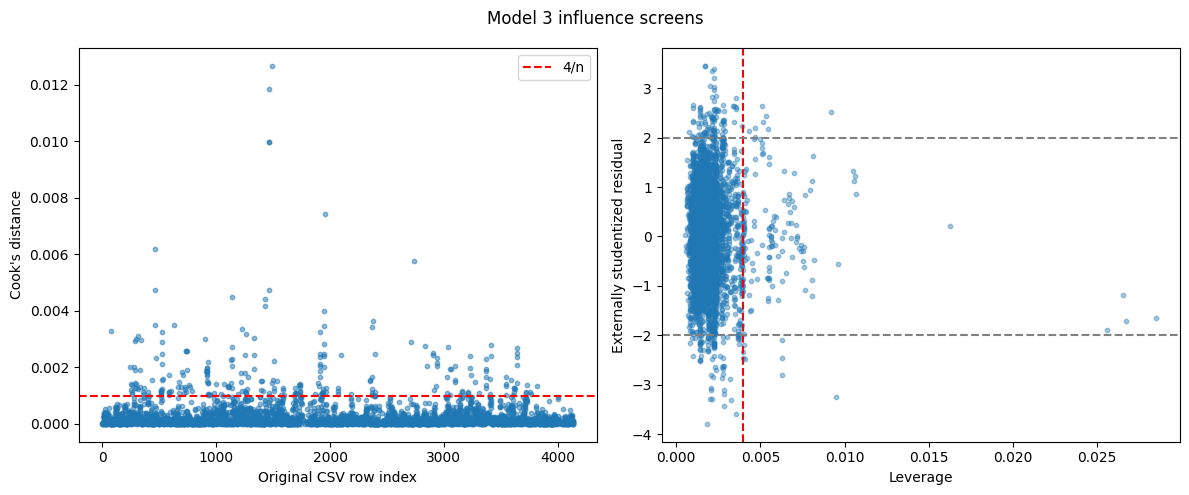

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(diagnostics.index, diagnostics["cooks_d"], s=10, alpha=0.5)
axes[0].axhline(cook_cutoff, color="red", linestyle="--", label="4/n")
axes[0].set_xlabel("Original CSV row index")
axes[0].set_ylabel("Cook's distance")
axes[0].legend()
axes[1].scatter(diagnostics["hat_diag"], diagnostics["studentized_residual"],
                s=10, alpha=0.4)
axes[1].axvline(leverage_cutoff, color="red", linestyle="--")
axes[1].axhline(2, color="grey", linestyle="--")
axes[1].axhline(-2, color="grey", linestyle="--")
axes[1].set_xlabel("Leverage")
axes[1].set_ylabel("Externally studentized residual")
fig.suptitle("Model 3 influence screens")
fig.tight_layout()
plt.show()

The screens flag **249/4,016** spaces by Cook's distance, **136/4,016** by leverage, and **189/4,016** by studentized residuals; these groups overlap. The highest Cook's distance is about **0.01266** for **CB3699, 601 MAIN ST**. Several high-leverage spaces share small downtown tracts, so I inspect identifiers and context rather than deleting records automatically.

DFBETAS is required by the assignment, but no DFBETAS example was found in the available lecture notebooks or course lab. I leave that specific requirement outstanding under the lecture-only restriction, rather than introduce an unreviewed technique.

## 7. Check sensitivity to Cook's-distance flags

I refit the same seven-variable specification after excluding only spaces above 4/n for Cook's distance. This is a sensitivity comparison, not a new cleaning rule, and I keep the 4,016-space fit as primary. Fit statistics across different samples do not establish that the screened sample is a better model.

In [16]:
keep = diagnostics["cooks_d"] <= cook_cutoff
model3_sensitivity = sm.OLS(y.loc[keep], X3.loc[keep]).fit()

sensitivity = pd.DataFrame({
    "Sample": ["Full sample (primary)", "Cook <= 4/n (sensitivity)"],
    "N": [int(model3.nobs), int(model3_sensitivity.nobs)],
    "Price coefficient": [model3.params["price_midpoint"],
                          model3_sensitivity.params["price_midpoint"]],
    "Price p-value": [model3.pvalues["price_midpoint"],
                      model3_sensitivity.pvalues["price_midpoint"]],
    "Adjusted R2": [model3.rsquared_adj, model3_sensitivity.rsquared_adj]
})
sensitivity.style.format({
    "Price coefficient": "{:.6f}", "Price p-value": "{:.3e}", "Adjusted R2": "{:.5f}"
})

,Sample,N,Price coefficient,Price p-value,Adjusted R2
0,Full sample (primary),4016,0.055633,4.731e-115,0.27235
1,Cook <= 4/n (sensitivity),3767,0.054769,1.393e-133,0.36202


In [17]:
sensitivity_coefficients = pd.DataFrame({
    "Full-sample coefficient": model3.params,
    "Sensitivity coefficient": model3_sensitivity.params,
    "Sensitivity p-value": model3_sensitivity.pvalues
})
sensitivity_coefficients.style.format({
    "Full-sample coefficient": "{:.6g}", "Sensitivity coefficient": "{:.6g}",
    "Sensitivity p-value": "{:.3e}"
})

,Full-sample coefficient,Sensitivity coefficient,Sensitivity p-value
const,0.456337,0.48932,2.835e-222
price_midpoint,0.0556328,0.054769,1.393e-133
time_limit_hours,0.00487929,0.0027943,2.905e-01
population_density,4.57052e-06,5.30055e-06,4.065e-132
nearby_restaurant_retail_count,-0.000321282,-0.000390916,2.212e-72
drive_alone_share,-0.198101,-0.247766,2.910e-39
transit_share,0.0196471,-0.03217,4.334e-01
RateType_TOD,0.0330042,0.0339612,7.397e-07


Excluding 249 flagged spaces leaves **3,767** observations. Price changes from **0.05563 to 0.05477**—about **5.56 to 5.48 percentage points per $1**—and remains positive with a small conventional p-value. The registration-count and drive-alone coefficients become more negative, while the uncertain transit estimate changes sign, so not every coefficient is equally stable.

Adjusted R² rises from 0.27235 to 0.36202, but the sample was selected using residual influence, which can mechanically improve fit. These p-values remain conventional and do not resolve the heteroskedasticity or dependence concerns. No observations are removed from the source file or the primary model.

<a id="rubric-4e"></a>

## 4(e) Robustness: 1,000-Replication Bootstrap vs. OLS

**Requirement:** Bootstrap coefficients 1,000 times and compare to OLS.

**Method:** Retain row resampling with seed 90095, all coefficient comparisons and the price histogram.

**Evidence:** Original 07 cells 35–38.

**Interpretation:** The row bootstrap holds selection fixed and assumes independent rows.

**Status: Complete.** 

## 8. Bootstrap the preferred specification

I follow the row-resampling examples in Lectures 1–2: sample with replacement, fit the same model, and record its coefficients for **1,000 replications**, with seed **90095**. I summarize all coefficients to match the assignment, then focus on price. This holds the selected specification fixed rather than rerunning variable selection in every draw.

In [18]:
np.random.seed(90095)
n_boot = 1000
bootstrap_coefficients = []

for i in range(n_boot):
    sample = data.sample(n=len(data), replace=True)
    X_boot = sm.add_constant(sample[predictors])
    bootstrap_model = sm.OLS(sample["occupancy_rate"], X_boot).fit()
    bootstrap_coefficients.append(bootstrap_model.params)

bootstrap = pd.DataFrame(bootstrap_coefficients)
print("Bootstrap replications:", len(bootstrap))
bootstrap_summary = pd.DataFrame({
    "Original OLS": model3.params,
    "Bootstrap mean": bootstrap.mean(),
    "Bootstrap SE": bootstrap.std(ddof=1),
    "Percentile 95% lower": bootstrap.quantile(0.025),
    "Percentile 95% upper": bootstrap.quantile(0.975)
})
bootstrap_summary.style.format("{:.6g}")

Bootstrap replications: 1000


,Original OLS,Bootstrap mean,Bootstrap SE,Percentile 95% lower,Percentile 95% upper
const,0.456337,0.456724,0.017315,0.422518,0.49125
price_midpoint,0.0556328,0.0554847,0.00237433,0.0509139,0.0601064
time_limit_hours,0.00487929,0.0049741,0.00314588,-0.000987099,0.0110299
population_density,4.57052e-06,4.58343e-06,2.35249e-07,4.11908e-06,5.07294e-06
nearby_restaurant_retail_count,-0.000321282,-0.000321162,2.41982e-05,-0.000371127,-0.000273167
drive_alone_share,-0.198101,-0.199397,0.0213658,-0.244678,-0.157657
transit_share,0.0196471,0.0202927,0.0445782,-0.0653932,0.102353
RateType_TOD,0.0330042,0.0327779,0.0086254,0.0160399,0.0487384


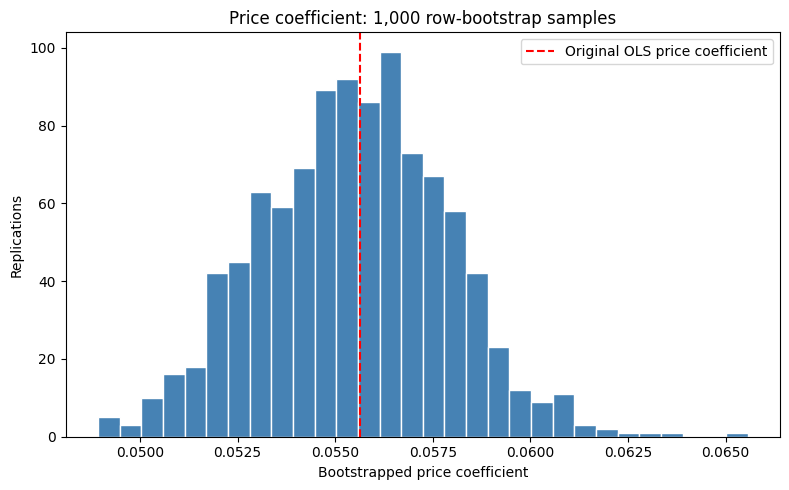

In [19]:
plt.figure(figsize=(8, 5))
plt.hist(bootstrap["price_midpoint"], bins=30, color="steelblue", edgecolor="white")
plt.axvline(model3.params["price_midpoint"], color="red", linestyle="--",
            label="Original OLS price coefficient")
plt.xlabel("Bootstrapped price coefficient")
plt.ylabel("Replications")
plt.title("Price coefficient: 1,000 row-bootstrap samples")
plt.legend()
plt.tight_layout()
plt.show()

The original price coefficient is **0.05563**; the bootstrap mean is **0.05548**, with bootstrap standard error **0.002374** and percentile interval **[0.05091, 0.06011]**. In percentage-point units per dollar, the interval is approximately **[5.09, 6.01]**, supporting stability of the positive association under this resampling scheme.

Ordinary row bootstrap treats spaces as independent even though the sample spans only 45 tracts and several predictors are shared within tracts. I found no tract-clustered inference example in the available lectures, so I document that dependence limitation rather than add a new estimator. The bootstrap does not fix endogeneity, mixed data vintages, or functional-form problems.

<a id="rubric-4f"></a>

## 4(f) Validation: 5-Fold or 10-Fold Cross-Validation and Out-of-Sample Accuracy

**Requirement:** Perform five- or ten-fold validation and report held-out accuracy.

**Method:** Link actual five-fold training-only fits in Section 3(e), preserving the original reference table here.

**Evidence:** Section 3(e), original 06 cells 24–28; original 07 cells 39–41 below.

**Interpretation:** Mean Model 3 held-out RMSE is 0.16532; this is not an untouched test of selection or new-neighborhood performance.

**Status: Complete.** 

## 9. Reference the existing cross-validation results

Notebook 06, Section 8, already performs the required five-fold comparison with seed 10, identical folds across models, and training-only fits for held-out predictions. The assignment asks for five **or** ten folds, so I do not repeat that analysis or add ten folds unnecessarily. The following values are copied from its executed output, not reestimated here.

In [20]:
cv_reference = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "Mean held-out RMSE (Notebook 06)": [0.17756, 0.16821, 0.16532]
})
cv_reference

,Model,Mean held-out RMSE (Notebook 06)
0,Model 1,0.17756
1,Model 2,0.16821
2,Model 3,0.16532


Model 3 has the lowest mean error, about **16.53 percentage points in root-mean-square terms**. Random-fold validation can place nearby spaces and the same tract in training and test data, and Notebook 05 used this sample for selection. It is a comparison of the fixed models for held-out spaces, not proof of performance in new neighborhoods or independent validation of the whole selection process.

<a id="rubric-4g"></a>

## 4(g) OLS Assumption Violations and Implications

**Requirement:** Document violations and discuss implications.

**Method:** Retain coverage/sample checks, diagnostic summary, assumptions and remaining raw-sensor work.

**Evidence:** Original 07 cells 42–51; final results diagnostic/robustness discussion in Section 5 supplementary material.

**Interpretation:** Variance and specification violations, spatial dependence and bounded predictions qualify inference; sensor rebuilds remain unexecuted.

**Status: Complete.** 

## 10. Check coverage and feasible sample sensitivities

The primary outcome uses intervals at most 24 hours and at least 25 transaction-active days. I first inspect recorded coverage; these checks do not change the sample. I then use the existing data for a stricter 28-day sample and for an income-missingness comparison, keeping the original sample primary.

In [21]:
print("Transaction-active days in the primary sample:")
print(parking.loc[data.index, "active_days"].value_counts().sort_index())

valid_month_fraction = parking.loc[data.index, "total_minutes"] / (31 * 24 * 60)
valid_month_fraction.describe()

Transaction-active days in the primary sample:
active_days
25     356
26    2032
27      19
28      45
29      89
30     184
31    1291
Name: count, dtype: int64


count    4016.000000
mean        0.822536
std         0.117815
min         0.315420
25%         0.741356
50%         0.775555
75%         0.966179
max         0.999898
Name: total_minutes, dtype: float64

Retained valid minutes average **82.25%** of August, with a median of **77.56%** and a minimum of **31.54%**. Active days do not necessarily mean fully monitored days, and the earlier raw audit found Sunday-reporting differences. A 28-day restriction is feasible using the saved active-day count; expanding to 20 days or changing interval cutoffs requires rebuilding the sensor outcomes.

In [22]:
days_data = data.loc[parking.loc[data.index, "active_days"].ge(28)].copy()
days_model = sm.OLS(days_data["occupancy_rate"], sm.add_constant(days_data[predictors])).fit(cov_type="HC1")
income_data = parking[["occupancy_rate", *predictors]].dropna()
income_model = sm.OLS(income_data["occupancy_rate"], sm.add_constant(income_data[predictors])).fit(cov_type="HC1")

sample_checks = pd.DataFrame([
    ["Primary common sample", model3_hc1],
    ["At least 28 active days", days_model],
    ["Retain missing-income spaces", income_model]
], columns=["Sample", "Fit"])
sample_summary = pd.DataFrame({
    "Sample": sample_checks["Sample"],
    "N": [int(m.nobs) for m in sample_checks["Fit"]],
    "Price coefficient": [m.params["price_midpoint"] for m in sample_checks["Fit"]],
    "HC1 95% lower": [m.conf_int().loc["price_midpoint", 0] for m in sample_checks["Fit"]],
    "HC1 95% upper": [m.conf_int().loc["price_midpoint", 1] for m in sample_checks["Fit"]],
    "Adjusted R2": [m.rsquared_adj for m in sample_checks["Fit"]]
})
sample_summary.round(6)

,Sample,N,Price coefficient,HC1 95% lower,HC1 95% upper,Adjusted R2
0,Primary common sample,4016,0.055633,0.051081,0.060184,0.272354
1,At least 28 active days,1609,0.049628,0.041057,0.058199,0.204005
2,Retain missing-income spaces,4060,0.057162,0.052560,0.061763,0.270828


The 28-day sample contains **1,609** spaces and gives a price coefficient of **0.04963**, versus **0.05563** in the primary sample. Restoring the 44 missing-income spaces gives **4,060** observations and a coefficient of **0.05716**; income is not a regressor, so this needs no imputation. Both comparisons retain a positive association, but the 28-day restriction changes sample composition and does not test a different interval definition.

### Processing needed before the sensor checks can proceed

The input for the remaining checks is `data/raw/ladot_occupancy/20261017T052111914317Z/Sensor Transactions_2025_08.csv`, containing **3,707,820 transactions**. I would parse the existing local timestamp format, sort within SpaceID, compute the next-record interval before excluding UNKNOWN states, and aggregate occupied/valid minutes separately under 12-, 24-, and 48-hour cutoffs. Raw active days would be counted before applying 20-, 25-, and 28-day restrictions.

The expanded samples would then need verified meter/predictor linkage; newly eligible spaces may lack the neighborhood predictors saved for the original sample. Comparisons should distinguish a common-space change in Y from a change in sample composition, and any new outputs must use separate paths. This raw-data rebuild requires approval under the task instructions, so it is **not implemented**. These comparisons are useful project robustness checks, not separately named requirements in the assignment. All existing datasets remain unchanged.

## 11. Summarize the diagnostics and remaining requirements

I combine the tests and robustness checks below, keeping screening rules distinct from decisions to change the data. A normality test that does not reject does not offset the variance and functional-form concerns. The price association is stable in the completed sensitivity checks, but its interpretation remains conditional and noncausal.

In [23]:
diagnostic_summary = pd.DataFrame([
    ["Residual plots", "Uneven spread; tract bands", "Inspect variance and mean specification", "Yes"],
    ["Jarque–Bera", f"p = {jb[1]:.3g}", "Do not reject normality at 5%", "Review with other assumptions"],
    ["Breusch–Pagan LM", f"p = {bp[1]:.3e}", "Reject constant variance", "Yes; HC1 comparison shown"],
    ["White LM", f"p = {white[1]:.3e}", "Reject constant variance", "Yes"],
    ["RESET", f"p = {float(reset.pvalue):.3e}", "Possible functional-form problem", "Yes"],
    ["Influence", f"{diagnostics['cook_flag'].sum()} Cook flags / {n}", "Screening flags, not confirmed errors", "Review identified spaces"],
    ["Cook sensitivity", f"Price = {model3_sensitivity.params['price_midpoint']:.5f}", "Positive price association remains", "Keep full sample primary"],
    ["Row bootstrap", f"{len(bootstrap):,} draws; price CI [{bootstrap_summary.loc['price_midpoint', 'Percentile 95% lower']:.5f}, {bootstrap_summary.loc['price_midpoint', 'Percentile 95% upper']:.5f}]", "Positive interval; independence assumed", "Dependence remains unresolved"],
    ["Five-fold CV", "Model 3 mean RMSE 0.16532 (Notebook 06)", "Best of the three fixed models", "New-neighborhood validity unresolved"],
    ["Log-density check", f"Price = {log_model.params['price_midpoint']:.5f}; RESET p = {float(log_reset.pvalue):.3e}", "Price stable; RESET still rejects", "Keep original Model 3 primary"],
    ["28 active days", f"N = {int(days_model.nobs)}; price = {days_model.params['price_midpoint']:.5f}", "Positive association in a stricter sample", "Does not change interval definition"],
    ["Income-missingness sensitivity", f"N = {int(income_model.nobs)}; price = {income_model.params['price_midpoint']:.5f}", "Retaining missing-income spaces preserves sign", "Keep original common sample primary"],
    ["Other sensor thresholds", "12/48-hour and 20-day alternatives not rebuilt", "Coverage rules may affect Y and sample", "Approval needed for raw-data rebuild"]
], columns=["Diagnostic", "Result", "Interpretation", "Further investigation"])
diagnostic_summary

,Diagnostic,Result,Interpretation,Further investigation
0,Residual plots,Uneven spread; tract bands,Inspect variance and mean specification,Yes
1,Jarque–Bera,p = 0.147,Do not reject normality at 5%,Review with other assumptions
2,Breusch–Pagan LM,p = 3.374e-41,Reject constant variance,Yes; HC1 comparison shown
3,White LM,p = 4.755e-63,Reject constant variance,Yes
4,RESET,p = 5.605e-28,Possible functional-form problem,Yes
5,Influence,249 Cook flags / 4016,"Screening flags, not confirmed errors",Review identified spaces
6,Cook sensitivity,Price = 0.05477,Positive price association remains,Keep full sample primary
7,Row bootstrap,"1,000 draws; price CI [0.05091, 0.06011]",Positive interval; independence assumed,Dependence remains unresolved
8,Five-fold CV,Model 3 mean RMSE 0.16532 (Notebook 06),Best of the three fixed models,New-neighborhood validity unresolved
9,Log-density check,Price = 0.05516; RESET p = 1.416e-19,Price stable; RESET still rejects,Keep original Model 3 primary


The full-sample price coefficient remains about **5.56 percentage points per $1**, and its row-bootstrap and HC1 intervals exclude zero. However, strong heteroskedasticity and RESET rejection mean I should not describe the original linear model as fully validated. HC1 addresses heteroskedastic uncertainty under independence, not shared-tract dependence, functional form, or demand-responsive pricing.

The October 2026 price proxy and business registrations also differ in timing and meaning from August 2025 occupancy. I keep the full 4,016-space Model 3 as the primary result and report the limitations before any final interpretation. No influential-observation screen becomes a permanent deletion rule, and the log-density alternative is only a robustness check; it does not remove the RESET concern.

### Assignment compliance and lecture coverage

| Requirement | Current status |
|---|---|
| Reproduce the common sample and Models 1–3 | Completed here; matches Notebook 06 |
| Residual plots, scale-location plot, normal Q-Q plot and Jarque–Bera | Completed here using Lectures 1–2 |
| Breusch–Pagan, White and Ramsey RESET | Completed here using Lecture 2 |
| Heteroskedasticity-consistent uncertainty | HC1 completed using worked Lecture 2 code; HC3 is named but not demonstrated as a worked comparison |
| Cook's distance, leverage, studentized residuals and influence sensitivity | Completed here; 4/n is the requested project screen, and the leverage/studentized rules appear in Lecture 1 |
| DFBETAS | Required by the assignment but not found in the available lecture examples; still outstanding |
| Bootstrap coefficient estimates, 1,000 replications, compared with OLS | Completed here for all Model 3 coefficients, with price histogram and percentile interval |
| Five- or ten-fold validation and prediction accuracy | Already completed in Notebook 06; referenced here without repeating fits |
| Descriptive statistics, standard EDA plots and missingness | Notebook 04 plus predictor Q-Q/density plots and Profiling in Notebook 08; income-missingness sensitivity shown here |
| Boruta, Mallows' Cp and VIF | Completed in Notebook 05; redundant best-eight display removed |
| Model comparison, coefficient interpretation and confidence intervals | Completed in Notebook 06, with additional uncertainty/sensitivity checks here |
| Assignment specification alignment | Model 2 corrected to three predictors; Model 3 keeps the original seven, including two insignificant terms, with justification in Notebooks 06 and 08 |
| Sensor-cutoff/day/Sunday robustness | 28-active-day sensitivity completed here; 12/48-hour, 20-day and Sunday checks still need raw-data work |
| Tract-clustered uncertainty | No worked example found in the available lectures; shared-neighborhood dependence remains a limitation |
| Economic literature, final policy/external-validity discussion, references and final presentation | Completed in Notebook 08; remaining submission gaps are listed there |
| PDF/HTML group submission with names and source code | Still outstanding |

The computational and statistical methods used here follow the reviewed lectures, apart from the Cook's 4/n screen explicitly supplied in the project instructions. I do not implement DFBETAS or clustered inference without course support. No raw or processed files are changed.

## Section Summary and Rubric Coverage

All listed diagnostic components have saved evidence except DFBETAS (Missing), making 4(d) Partial. Five-fold evidence is implemented in Section 3(e), not generated by this notebook’s reference table. Raw-sensor rebuilds remain additional uncompleted work.

Preserved outputs record earlier execution, not a claim that this migrated workflow has been rerun. See [validation evidence](../docs/notebook_validation_summary.md) for fresh execution results and blockers, and the [rubric audit](../docs/rubric_compliance_audit.md) for evidence-backed component status.